# Tutorial Passo 4: Trabalhando no domínio da frequência

Trabalhar no domínio do tempo muitas vezes não é conveniente; por isso, é importante estar familiarizado com o domínio da frequência.
O [domínio da frequência](https://en.wikipedia.org/wiki/Frequency_domain) é uma representação de séries temporais que mostra como o sinal se distribui em diferentes bandas de frequência ao longo de uma faixa de frequências (o chamado "espectro" de um sinal).
Trabalhar no domínio da frequência é mais conveniente para operações comuns, como filtragem ou identificação de sinais.
É possível transformar um sinal do domínio do tempo para o domínio da frequência e vice-versa.

<div class="alert alert-block alert-warning">
<div><b>&#9888; Warning</b></div>
Remova o comentário da célula a seguir se estiver executando no Google Colab. 
Se utilizar outros métodos de execução, isso não deve ser necessário.
</div>

In [1]:
#! wget http://gwosc.org/archive/data/O3b_4KHZ_R1/1263534080/H-H1_GWOSC_O3b_4KHZ_R1-1264312320-4096.hdf5

Antes de prosseguir, vamos voltar ao nosso exemplo anterior (não há nada de novo no código abaixo):

In [1]:
#----------------------
# Import needed modules
#----------------------
import numpy as np
import matplotlib.pylab as plt
import matplotlib.mlab as mlab
import h5py

#----------
# Open file
#----------
fileName = 'H-H1_GWOSC_O3b_4KHZ_R1-1264312320-4096.hdf5'
dataFile = h5py.File(fileName, 'r')

#-------------------------------------
# Read the strain and some information
#-------------------------------------
strain   = dataFile['strain']['Strain']
ts       = dataFile['strain']['Strain'].attrs['Xspacing']
meta     = dataFile['meta']
gpsStart = meta['GPSstart'][()]
duration = meta['Duration'][()]
gpsEnd   = gpsStart + duration
time     = np.arange(gpsStart, gpsEnd, ts)

#-----------------------------
# Extract a part of the signal
#-----------------------------
length     = 16     # Length in second
startTime  = 1264316116.0
numsamples = int(length / ts)
startIndex = np.min(np.nonzero(startTime < time))
time_seg   = time[startIndex:(startIndex+numsamples)]
strain_seg = strain[startIndex:(startIndex+numsamples)]

Um conceito importante quando se trabalha no domínio da frequência é a noção de [frequência da amostragem](https://en.wikipedia.org/wiki/Sampling_(signal_processing)).
Isso é simplesmente o inverso do tempo entre duas amostras.
Vamos armazenar isso em uma variável chamada `fs`.

In [2]:
# Frequência de amostragem
fs = int(1.0 / ts)

## FFT with Blackman Window

A Transformada Rápida de Fourier, ou FFT, é um método para transformar os dados para o domínio da frequência.
Um conceito importante ao calcular a FFT é [windowing](https://en.wikipedia.org/wiki/Window_function).
Isso se refere ao uso de uma função (chamada window function) para forçar suavemente os dados a zero nos limites de tempo e, assim, reduzir os efeitos de borda na FFT.
Diferentes window functions têm propriedades diferentes.
Aqui, usaremos a [Blackman Window](https://en.wikipedia.org/wiki/Window_function#Blackman_window).

Observa-se que o espectro de ruído dos instrumentos atuais apresenta maior potência em baixas frequências ($f < 50 Hz$), devido principalmente ao ruído sísmico.
A faixa de maior sensibilidade, frequentemente chamada de "The Bucket" (ou "a bacia"), situa-se aproximadamente entre 100 e 300 Hz.

Text(0, 0.5, 'Strain / Hz')

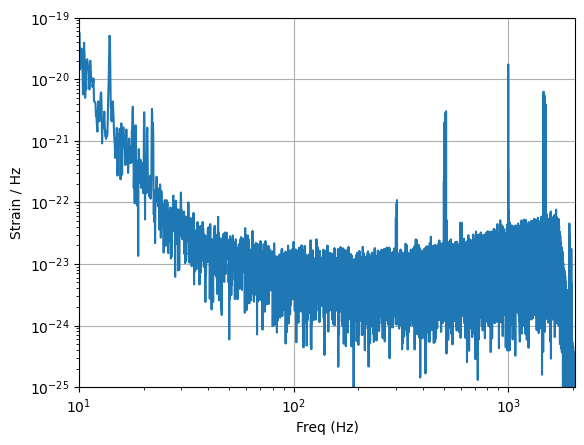

In [3]:
#------------------------------------------
# Apply a Blackman Window, and plot the FFT
#------------------------------------------
window          = np.blackman(strain_seg.size)
windowed_strain = strain_seg * window
freq_domain     = np.fft.rfft(windowed_strain) / fs
freq            = np.fft.rfftfreq(len(windowed_strain)) * fs    
plt.loglog(freq, abs(freq_domain))
plt.axis([10, fs/2.0, 1e-25, 1e-19])
plt.grid('on')
plt.xlabel('Freq (Hz)')
plt.ylabel('Strain / Hz')

## Power Spectral Density (PSD) and Amplitude Spectral Density (ASD) 
##  (Densidade Espectral de Potência (PSD) e Densidade Espectral de Amplitude (ASD))

A Densidade Espectral de Potência é outra representação de como a potência nos dados é distribuída no espaço de frequência.
A [`psd`](https://matplotlib.org/stable/api/mlab_api.html#matplotlib.mlab.psd)  utiliza o método de Welch para estimar a PSD.
O método divide os dados em segmentos com `NFFT` amostras, calcula um periodograma de cada segmento (semelhante à FFT plotada acima) e, em seguida, calcula a média temporal dos periodogramas.
Essa média sobre vários segmentos reduz a variância do resultado, razão pela qual a PSD parece "mais fina" do que a FFT.

Text(0, 0.5, 'PSD')

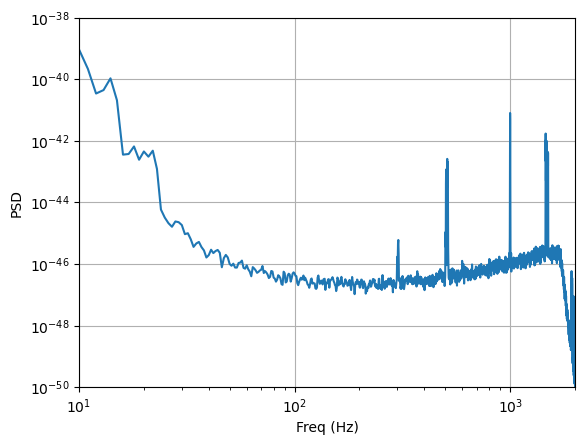

In [4]:
#-----------
# Make a PSD
#-----------
Pxx, freqs = mlab.psd(strain_seg, Fs=fs, NFFT=fs)
plt.loglog(freqs, Pxx)
plt.axis([10, 2000, 1e-50, 1e-38])
plt.grid('on')
plt.xlabel('Freq (Hz)')
plt.ylabel('PSD')

Uma variação é usar a raiz quadrada da PSD.
Isso é chamado de Densidade Espectral de Amplitude (ASD) e é feito para fornecer unidades que possam ser comparadas mais facilmente com os dados do domínio do tempo ou FFT.
Mais informações sobre a ASD dos instrumentos podem ser encontradas na página de cada conjunto de dados, geralmente em uma seção chamada "Linhas Espectrais Instrumentais" (veja [aqui](https://gwosc.org/O3/o3speclines/) para O3b).

Text(0, 0.5, 'ASD (Strain / Hz$^{1/2})$')

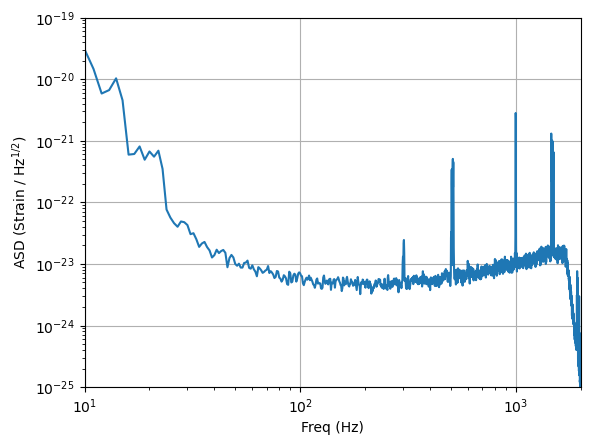

In [5]:
#-------------
# Plot the ASD
#-------------
plt.loglog(freqs, np.sqrt(Pxx))
plt.axis([10, 2000, 1e-25, 1e-19])
plt.grid('on')
plt.xlabel('Freq (Hz)')
plt.ylabel('ASD (Strain / Hz$^{1/2})$')

## Espectrograma

Trabalhar no domínio da frequência é importante, mas perdemos toda a noção de quando um evento pode ocorrer.
Intuitivamente, gostaríamos de estudar como a distribuição de frequências varia ao longo do tempo.
Os espectrogramas são uma forma de mostrar isso.

Text(0, 0.5, 'Freq (Hz)')

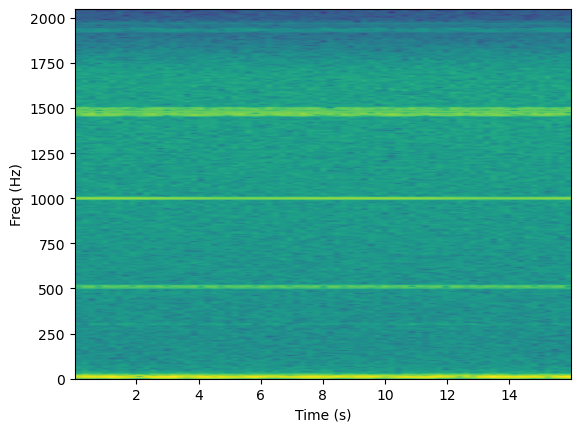

In [6]:
#-------------------
# Make a spectrogram
#-------------------
NFFT = 1024
short_window = np.blackman(NFFT)
spec_power, freqs, bins, im = plt.specgram(
    strain_seg, NFFT=NFFT, Fs=fs,
    window=short_window
)
plt.xlabel('Time (s)')
plt.ylabel('Freq (Hz)')

Principalmente, este espectrograma mostra o que já sabíamos pela PSD: há muito mais potência em frequências muito baixas do que em frequências altas.

## Qual é o próximo passo?

Muitos métodos usados nos pipelines LVK são baseados no domínio da frequência, por isso é importante estar familiarizado com essas ideias.

NO [próximo passo](<05 - GWpy Examples.ipynb>), você aprenderá a usar um pacote Python para facilitar a interação com os dados do GWOSC.